# Multi-Class Benchmark Classification Pipeline — Iris

**Goal:** build an end-to-end, leakage-free classification workflow with Scikit-Learn and benchmark
**Logistic Regression** against a **Decision Tree** on the Iris dataset.

| Step | What we do |
|---|---|
| 1 | Load the data with Pandas and sanity-check it |
| 2 | Exploratory analysis (pairplot, correlations, distributions) |
| 3 | Stratified 80/20 train/test split |
| 4 | `StandardScaler` + model wrapped in a `Pipeline` (so scaling is fit on training data only) |
| 5 | Train Logistic Regression and Decision Tree |
| 6 | Accuracy, precision, recall, F1 (per-class, macro, weighted) + classification reports |
| 7 | Confusion-matrix heatmaps |
| 8 | 5-fold cross-validation and light hyper-parameter tuning (the 30-sample test set is small) |
| 9 | Decision-boundary visualisation |
| 10 | Final benchmark table and conclusions |

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

## 1. Load the dataset

We load the Iris CSV straight from the URL given in the brief. If the network is unavailable the cell
falls back to the identical copy that ships with Scikit-Learn, so the notebook always runs.

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

try:
    df = pd.read_csv(URL)
    source = "URL"
except Exception as e:
    from sklearn.datasets import load_iris
    _iris = load_iris(as_frame=True)
    df = _iris.frame.rename(columns={
        "sepal length (cm)": "sepal_length", "sepal width (cm)": "sepal_width",
        "petal length (cm)": "petal_length", "petal width (cm)": "petal_width"})
    df["species"] = df["target"].map(dict(enumerate(_iris.target_names)))
    df = df.drop(columns="target")
    source = "scikit-learn fallback"

print(f"Loaded from: {source}  |  shape = {df.shape}")
df.head()

Loaded from: URL  |  shape = (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 1.1 Data quality checks

In [3]:
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicated rows:", df.duplicated().sum())
print()
df.info()

Missing values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64 

Duplicated rows: 1

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5


,samples
species,
setosa,50
versicolor,50
virginica,50


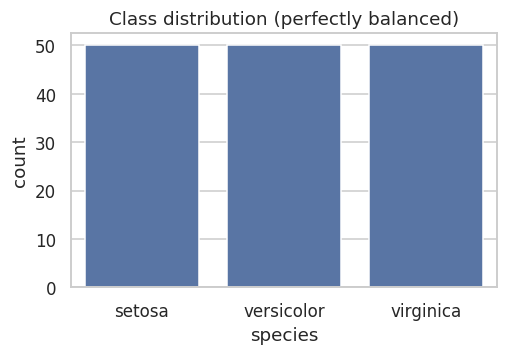

In [5]:
# Class balance
counts = df["species"].value_counts()
display(counts.to_frame("samples"))

fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(data=df, x="species", ax=ax)
ax.set_title("Class distribution (perfectly balanced)")
plt.show()

**Observations**
- 150 samples, 4 numeric features, 3 classes with exactly 50 samples each → accuracy is a fair headline metric, but we still report macro-averaged precision/recall/F1.
- No missing values. One exact duplicate row exists in the original Iris data; it is a genuine measurement, so we keep it (dropping it would change the benchmark's standard 150-sample definition).

## 2. Exploratory data analysis

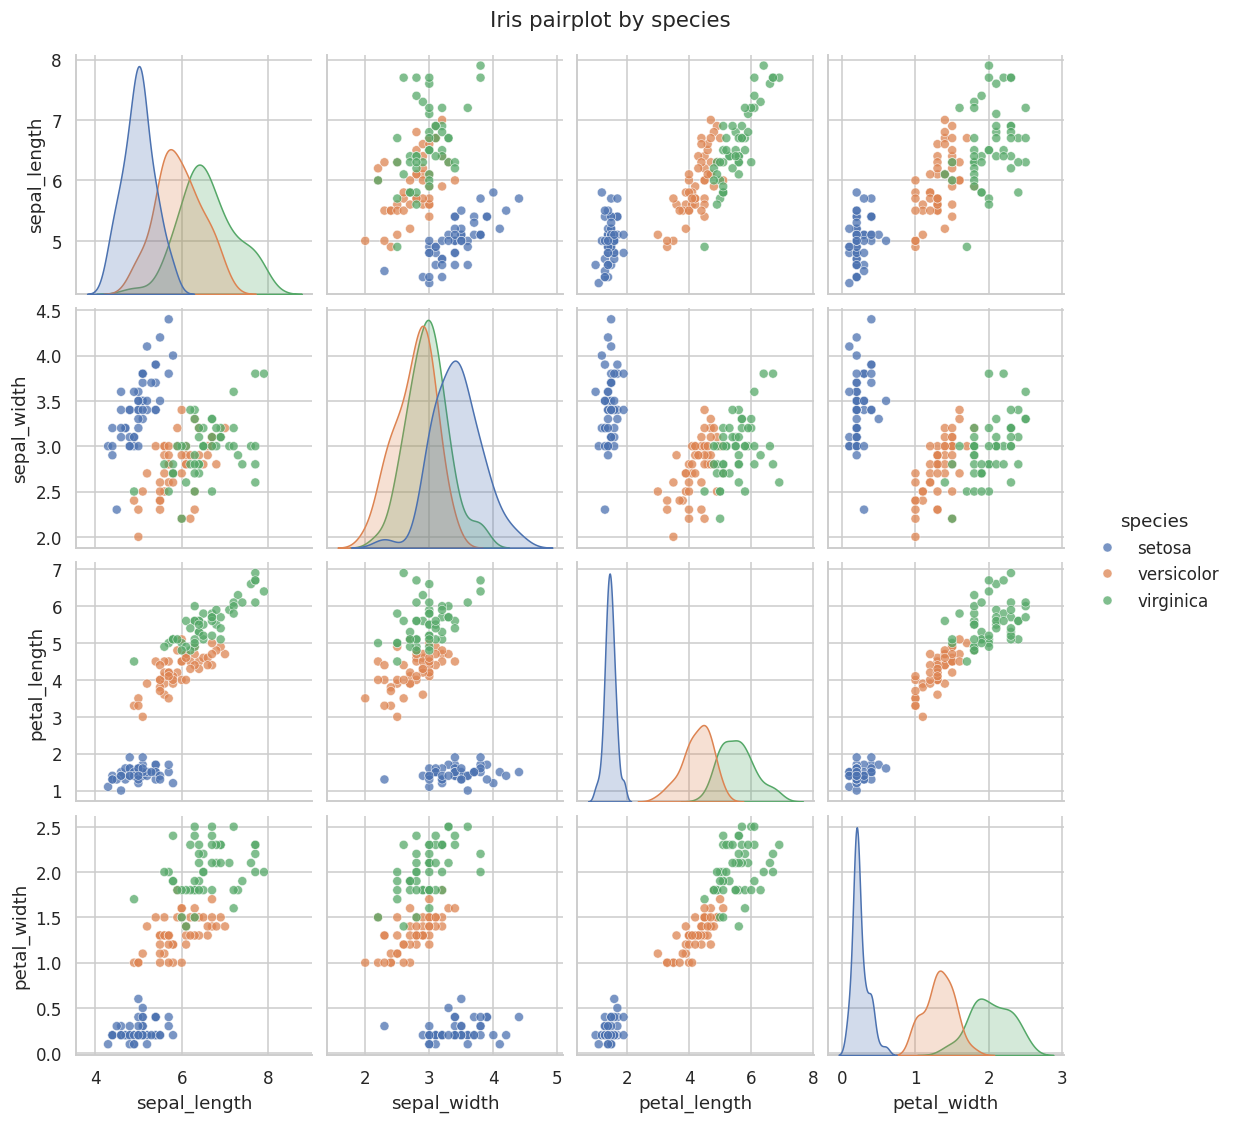

In [6]:
g = sns.pairplot(df, hue="species", diag_kind="kde", corner=False,
                 plot_kws=dict(alpha=0.75, s=35, edgecolor="white", linewidth=0.4))
g.fig.suptitle("Iris pairplot by species", y=1.02, fontsize=14)
plt.show()

**Reading the pairplot:** *setosa* is linearly separable from the other two on almost every pair, particularly on
petal length/width. *versicolor* and *virginica* overlap slightly — this overlap is where all of the classification
errors will come from. Petal measurements separate the classes far better than sepal measurements.

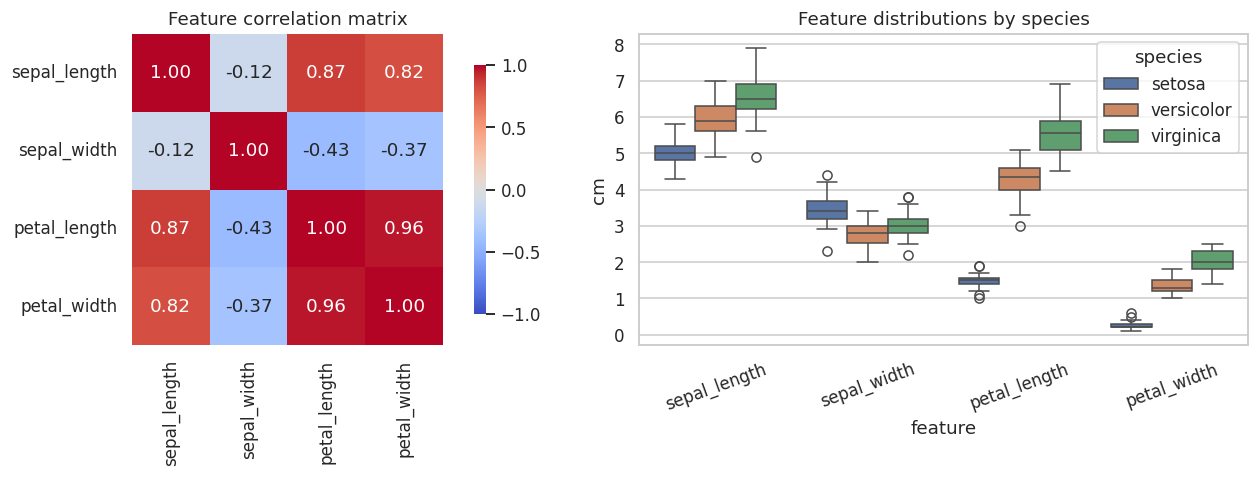

In [7]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": .8}, ax=axes[0])
axes[0].set_title("Feature correlation matrix")

melted = df.melt(id_vars="species", value_vars=features, var_name="feature", value_name="cm")
sns.boxplot(data=melted, x="feature", y="cm", hue="species", ax=axes[1])
axes[1].set_title("Feature distributions by species")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Petal length and petal width are very highly correlated (≈0.96) with each other and with the class label — good
for accuracy, and a reason to expect coefficients in Logistic Regression to be shared between those two features.

In [8]:
# Why scaling matters: the raw features live on different scales
display(df[features].agg(["mean", "std"]).T.round(3))

,mean,std
sepal_length,5.843,0.828
sepal_width,3.057,0.436
petal_length,3.758,1.765
petal_width,1.199,0.762


## 3. Train / test split (80 / 20)

- `stratify=y` keeps the 1/3-1/3-1/3 class ratio in both partitions.
- The split happens **before** any scaling. The scaler is later fit on the training set only, so no test-set
  statistics leak into training.

In [9]:
le = LabelEncoder()
y = le.fit_transform(df["species"])
class_names = list(le.classes_)
X = df[features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print("Classes:", dict(enumerate(class_names)))
print("Train class counts:", np.bincount(y_train), "| Test class counts:", np.bincount(y_test))

Train: (120, 4)   Test: (30, 4)
Classes: {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
Train class counts: [40 40 40] | Test class counts: [10 10 10]


## 4. Feature scaling with `StandardScaler`

Each feature is transformed to `z = (x − μ_train) / σ_train`. Logistic Regression is sensitive to feature scale
(regularisation and gradient-based optimisation), whereas Decision Trees are scale-invariant — we still put the scaler
in both pipelines so the two models are compared under an identical preprocessing recipe, as the brief requires.

Train means after scaling (≈0): [-0.0, 0.0, 0.0, 0.0]
Train stds  after scaling (≈1): [1.0, 1.0, 1.0, 1.0]


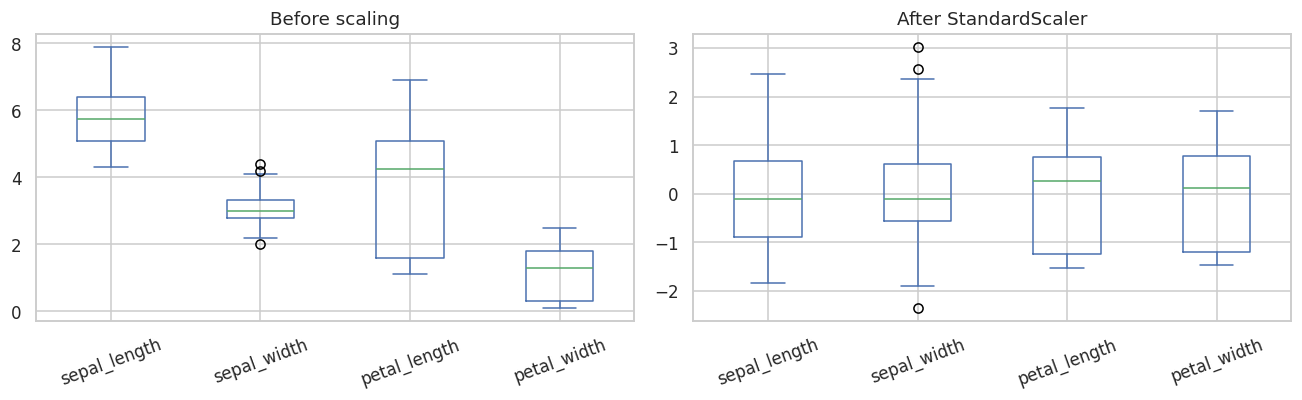

In [10]:
scaler = StandardScaler().fit(X_train)          # statistics from TRAIN only
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=features)

print("Train means after scaling (≈0):", X_train_s.mean().round(6).tolist())
print("Train stds  after scaling (≈1):", X_train_s.std(ddof=0).round(6).tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
X_train.plot.box(ax=axes[0]);   axes[0].set_title("Before scaling")
X_train_s.plot.box(ax=axes[1]); axes[1].set_title("After StandardScaler")
for a in axes: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 5. Build and train the models

Each model is a `Pipeline([StandardScaler, estimator])`, so `fit`/`predict` always applies the correct scaling
and cross-validation later re-fits the scaler inside every fold.

In [11]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print(f"✔ trained {name}")

✔ trained Logistic Regression
✔ trained Decision Tree


## 6. Evaluation on the held-out test set

For multi-class problems, precision / recall / F1 need an averaging strategy:
- **macro** – unweighted mean over classes (treats every class equally),
- **weighted** – mean weighted by class support.

Because Iris is balanced, the two are nearly identical.

In [12]:
preds = {name: pipe.predict(X_test) for name, pipe in models.items()}

rows = []
for name, yhat in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, yhat),
        "Precision (macro)": precision_score(y_test, yhat, average="macro"),
        "Recall (macro)": recall_score(y_test, yhat, average="macro"),
        "F1 (macro)": f1_score(y_test, yhat, average="macro"),
        "Precision (weighted)": precision_score(y_test, yhat, average="weighted"),
        "Recall (weighted)": recall_score(y_test, yhat, average="weighted"),
        "F1 (weighted)": f1_score(y_test, yhat, average="weighted"),
    })
results = pd.DataFrame(rows).set_index("Model")
results.round(4).style.background_gradient(cmap="Greens", axis=None, vmin=0.8, vmax=1.0).format("{:.4f}")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
Model,,,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333


### 6.1 Per-class classification reports

In [13]:
for name, yhat in preds.items():
    print("=" * 62)
    print(f" {name}")
    print("=" * 62)
    print(classification_report(y_test, yhat, target_names=class_names, digits=4))

 Logistic Regression


              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

 Decision Tree
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



## 7. Confusion-matrix heatmaps

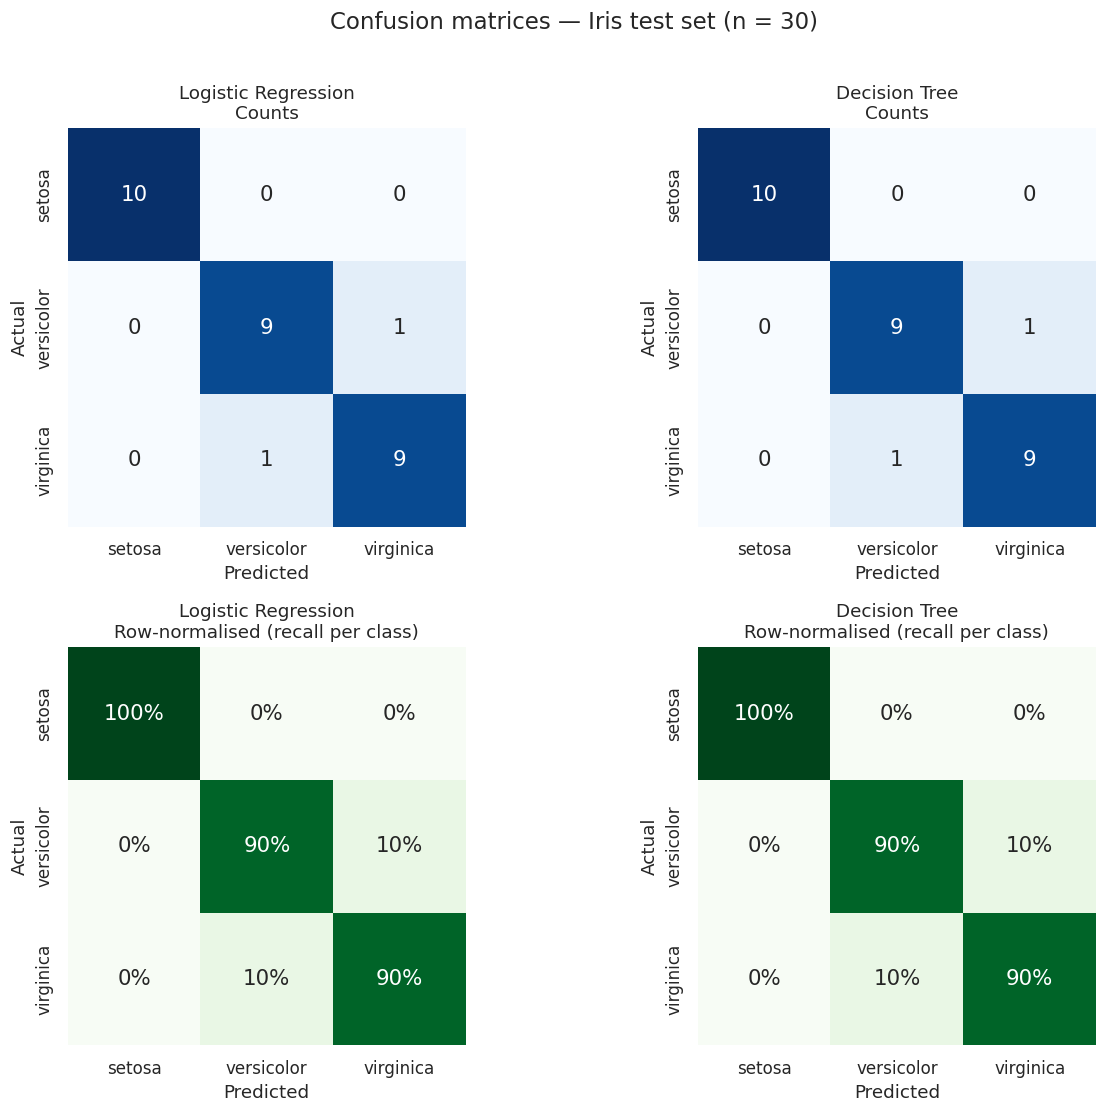

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for j, (name, yhat) in enumerate(preds.items()):
    cm = confusion_matrix(y_test, yhat)
    cm_norm = confusion_matrix(y_test, yhat, normalize="true")

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={"size": 14}, ax=axes[0, j])
    axes[0, j].set_title(f"{name}\nCounts")
    axes[0, j].set_xlabel("Predicted"); axes[0, j].set_ylabel("Actual")

    sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Greens", cbar=False, square=True, vmin=0, vmax=1,
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={"size": 14}, ax=axes[1, j])
    axes[1, j].set_title(f"{name}\nRow-normalised (recall per class)")
    axes[1, j].set_xlabel("Predicted"); axes[1, j].set_ylabel("Actual")

plt.suptitle("Confusion matrices — Iris test set (n = 30)", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

In [15]:
# Which test samples were misclassified?
for name, yhat in preds.items():
    wrong = np.where(yhat != y_test)[0]
    print(f"{name}: {len(wrong)} misclassified of {len(y_test)}")
    if len(wrong):
        out = X_test.iloc[wrong].copy()
        out["actual"] = [class_names[i] for i in y_test[wrong]]
        out["predicted"] = [class_names[i] for i in yhat[wrong]]
        display(out)

Logistic Regression: 2 misclassified of 30


,sepal_length,sepal_width,petal_length,petal_width,actual,predicted
134,6.1,2.6,5.6,1.4,virginica,versicolor
77,6.7,3.0,5.0,1.7,versicolor,virginica


Decision Tree: 2 misclassified of 30


,sepal_length,sepal_width,petal_length,petal_width,actual,predicted
134,6.1,2.6,5.6,1.4,virginica,versicolor
77,6.7,3.0,5.0,1.7,versicolor,virginica


## 8. Robustness: cross-validation and tuning

A 30-sample test set means **one** misclassified flower moves accuracy by 3.3 percentage points, so a single split can
easily over- or under-state a model. We therefore also report **stratified 5-fold cross-validation** on the
*training* partition (the scaler is re-fit inside every fold because it lives in the pipeline).

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision_macro": "precision_macro",
           "recall_macro": "recall_macro", "f1_macro": "f1_macro"}

cv_rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for k in scoring:
        row[f"{k} (mean)"] = s[f"test_{k}"].mean()
        row[f"{k} (std)"] = s[f"test_{k}"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(4)

,accuracy (mean),accuracy (std),precision_macro (mean),precision_macro (std),recall_macro (mean),recall_macro (std),f1_macro (mean),f1_macro (std)
Model,,,,,,,,
Logistic Regression,0.9583,0.0264,0.9644,0.0212,0.9583,0.0264,0.9580,0.0268
Decision Tree,0.9500,0.0167,0.9570,0.0119,0.9500,0.0167,0.9496,0.0171


### 8.1 Hyper-parameter tuning (`GridSearchCV`)

The default Decision Tree grows until every leaf is pure and will overfit; Logistic Regression's regularisation
strength `C` matters too. We tune on the **training set only** with CV, then evaluate the tuned models once on the test set.

In [17]:
param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10, 100]},
    "Decision Tree": {"clf__max_depth": [2, 3, 4, 5, None],
                      "clf__min_samples_leaf": [1, 2, 4, 8],
                      "clf__criterion": ["gini", "entropy"]},
}

tuned = {}
for name, grid in param_grids.items():
    gs = GridSearchCV(models[name], grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:20s} best CV F1-macro = {gs.best_score_:.4f}  |  best params = {gs.best_params_}")

Logistic Regression  best CV F1-macro = 0.9663  |  best params = {'clf__C': 10}


Decision Tree        best CV F1-macro = 0.9580  |  best params = {'clf__criterion': 'gini', 'clf__max_depth': 3, 'clf__min_samples_leaf': 1}


In [18]:
tuned_rows = []
for name, gs in tuned.items():
    yhat = gs.best_estimator_.predict(X_test)
    tuned_rows.append({
        "Model": f"{name} (tuned)",
        "Accuracy": accuracy_score(y_test, yhat),
        "Precision (macro)": precision_score(y_test, yhat, average="macro"),
        "Recall (macro)": recall_score(y_test, yhat, average="macro"),
        "F1 (macro)": f1_score(y_test, yhat, average="macro"),
    })
tuned_results = pd.DataFrame(tuned_rows).set_index("Model")
tuned_results.round(4)

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression (tuned),1.0000,1.0000,1.0000,1.0000
Decision Tree (tuned),0.9667,0.9697,0.9667,0.9666


## 9. Decision-boundary visualisation

A 4-feature model cannot be drawn on a plane, so we retrain both pipelines on the two most discriminative features —
**petal length** and **petal width** — purely for visualisation. The shaded regions show the predicted class at each point;
circles are training samples and squares are test samples.

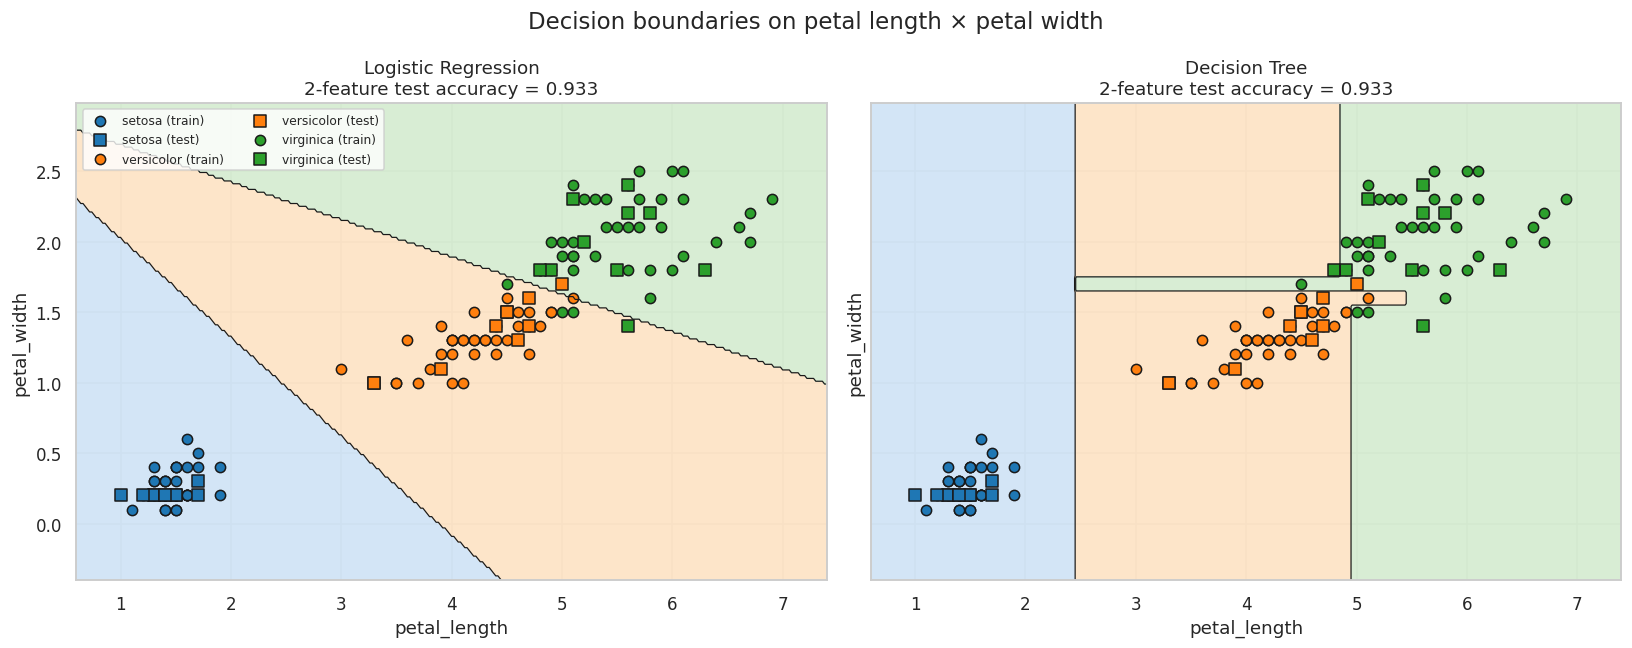

In [19]:
def plot_boundary(pipe, Xtr, ytr, Xte, yte, feats, ax, title, h=0.02):
    pipe.fit(Xtr[feats], ytr)
    x_min, x_max = Xtr[feats[0]].min() - .5, Xtr[feats[0]].max() + .5
    y_min, y_max = Xtr[feats[1]].min() - .5, Xtr[feats[1]].max() + .5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feats)
    Z = pipe.predict(grid).reshape(xx.shape)

    cmap_bg = plt.matplotlib.colors.ListedColormap(["#cfe3f5", "#fde3c4", "#d4ecd0"])
    cols = ["#1f77b4", "#ff7f0e", "#2ca02c"]
    ax.contourf(xx, yy, Z, cmap=cmap_bg, levels=[-.5, .5, 1.5, 2.5], alpha=.9)
    ax.contour(xx, yy, Z, levels=[.5, 1.5], colors="k", linewidths=.8)
    for k, cname in enumerate(class_names):
        m = ytr == k
        ax.scatter(Xtr[feats[0]][m], Xtr[feats[1]][m], c=cols[k], edgecolor="k", s=45, label=f"{cname} (train)")
        m = yte == k
        ax.scatter(Xte[feats[0]][m], Xte[feats[1]][m], c=cols[k], edgecolor="k", s=70, marker="s",
                   label=f"{cname} (test)")
    acc = accuracy_score(yte, pipe.predict(Xte[feats]))
    ax.set_title(f"{title}\n2-feature test accuracy = {acc:.3f}")
    ax.set_xlabel(feats[0]); ax.set_ylabel(feats[1])

feats2 = ["petal_length", "petal_width"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, (name, base) in zip(axes, models.items()):
    from sklearn.base import clone
    plot_boundary(clone(base), X_train, y_train, X_test, y_test, feats2, ax, name)
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
plt.suptitle("Decision boundaries on petal length × petal width", fontsize=15)
plt.tight_layout()
plt.show()

**Interpretation.** Logistic Regression produces smooth, **linear** boundaries (straight lines between classes), while the
Decision Tree produces **axis-aligned, rectangular** regions made of threshold splits. Both separate *setosa* cleanly; the
only contested territory is the versicolor/virginica border. Note the thin horizontal sliver the unconstrained tree carves
out around a couple of training points near petal width ≈ 1.7 — a visible symptom of **overfitting** (high variance) that the
smooth logistic boundary does not show.

## 10. Model interpretation

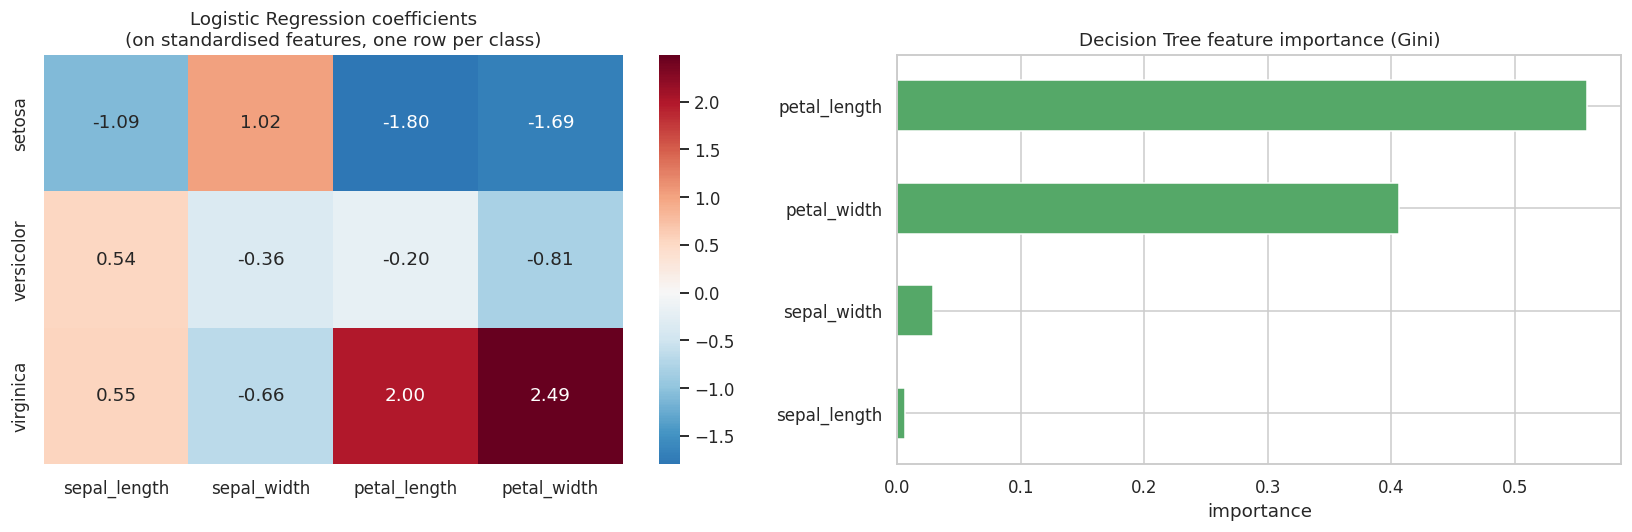

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Logistic regression: coefficients on standardised features (comparable magnitudes)
lr = models["Logistic Regression"].named_steps["clf"]
coef = pd.DataFrame(lr.coef_, index=class_names, columns=features)
sns.heatmap(coef, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Logistic Regression coefficients\n(on standardised features, one row per class)")

# Decision tree: feature importance
dt = models["Decision Tree"].named_steps["clf"]
imp = pd.Series(dt.feature_importances_, index=features).sort_values()
imp.plot.barh(ax=axes[1], color=sns.color_palette("deep")[2])
axes[1].set_title("Decision Tree feature importance (Gini)")
axes[1].set_xlabel("importance")
plt.tight_layout(); plt.show()

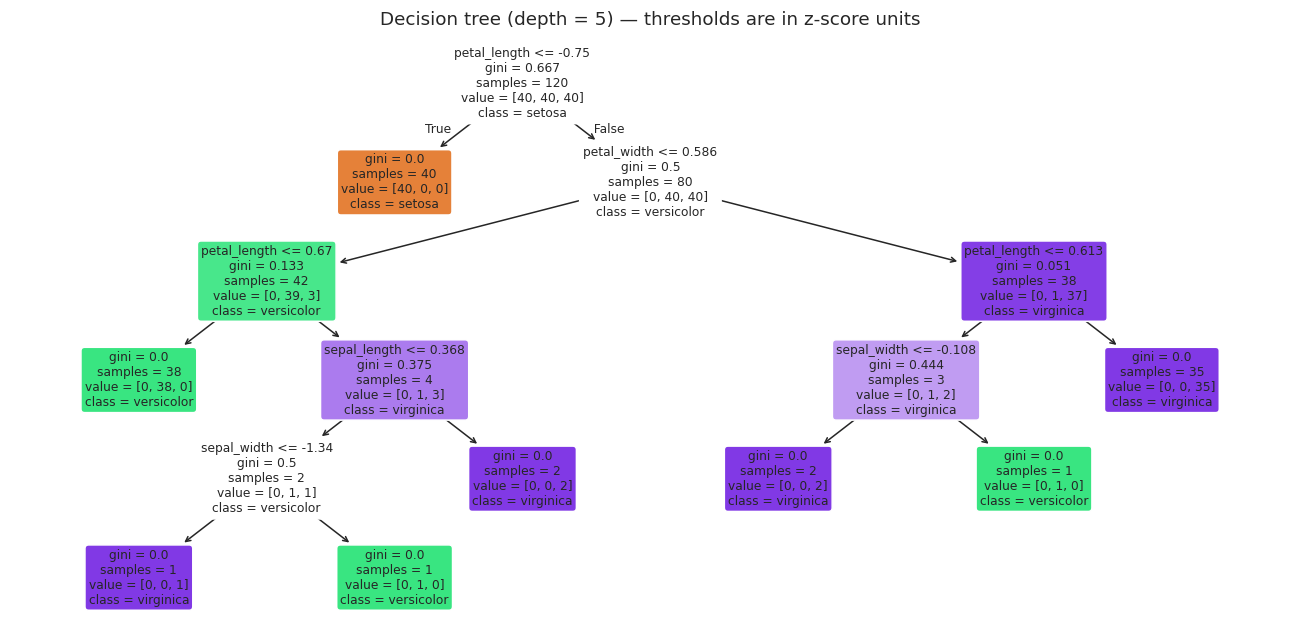

In [21]:
# Fitted (default) decision tree, drawn on the standardised feature space
models["Decision Tree"].fit(X_train, y_train)   # re-fit on all 4 features (boundary cell refit a clone only)
fig, ax = plt.subplots(figsize=(15, 7))
plot_tree(models["Decision Tree"].named_steps["clf"], feature_names=features, class_names=class_names,
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Decision tree (depth = {models['Decision Tree'].named_steps['clf'].get_depth()}) — thresholds are in z-score units")
plt.show()

## 11. Final benchmark summary

,Accuracy,Precision (macro),Recall (macro),F1 (macro),"CV F1 (macro, train)"
Model,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9580
Decision Tree,0.9333,0.9333,0.9333,0.9333,0.9496
Logistic Regression (tuned),1.0000,1.0000,1.0000,1.0000,0.9663
Decision Tree (tuned),0.9667,0.9697,0.9667,0.9666,0.9580


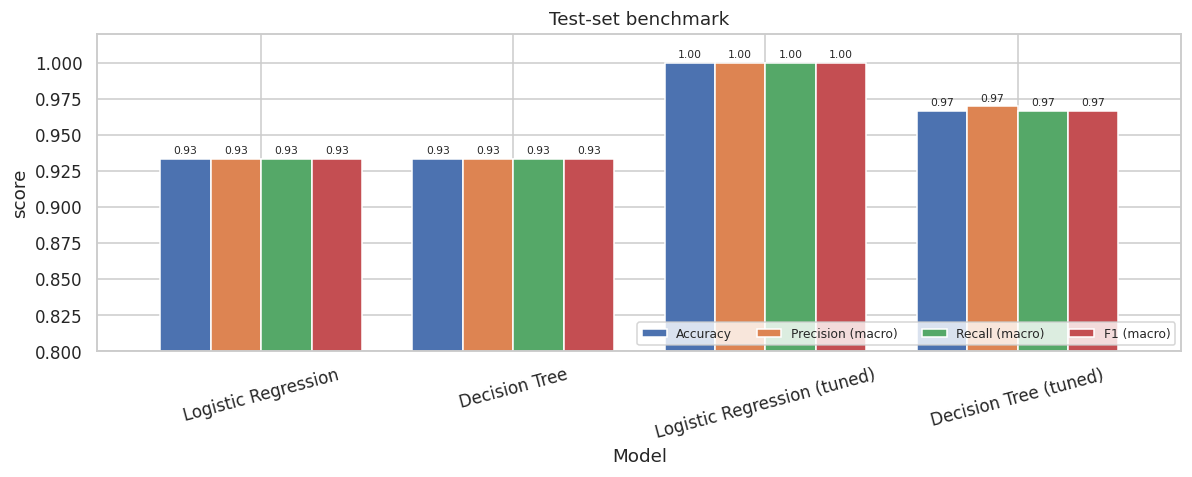

In [22]:
# Make sure the evaluated 'models' dict reflects the 4-feature fit for the final table
final_rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    yhat = pipe.predict(X_test)
    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, yhat),
        "Precision (macro)": precision_score(y_test, yhat, average="macro"),
        "Recall (macro)": recall_score(y_test, yhat, average="macro"),
        "F1 (macro)": f1_score(y_test, yhat, average="macro"),
    })
final = pd.concat([pd.DataFrame(final_rows).set_index("Model"), tuned_results])
final["CV F1 (macro, train)"] = [
    cv_results.loc["Logistic Regression", "f1_macro (mean)"],
    cv_results.loc["Decision Tree", "f1_macro (mean)"],
    tuned["Logistic Regression"].best_score_,
    tuned["Decision Tree"].best_score_,
]
display(final.round(4).style.background_gradient(cmap="Greens", axis=None, vmin=0.85, vmax=1.0).format("{:.4f}"))

ax = final.drop(columns="CV F1 (macro, train)").plot.bar(figsize=(11, 4.5), rot=15, width=.8)
ax.set_ylim(0.8, 1.02); ax.set_ylabel("score"); ax.set_title("Test-set benchmark")
ax.legend(loc="lower right", ncol=4, fontsize=8)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7, padding=2)
plt.tight_layout(); plt.show()

## 12. Conclusions

1. **Both default models score identically on the test split:** accuracy = macro-F1 = **0.933** (28/30 correct). *Setosa* is
   classified perfectly; the only errors are one *versicolor → virginica* and one *virginica → versicolor* confusion — exactly the
   overlap region seen in the pairplot.
2. **Cross-validation separates them slightly:** Logistic Regression ≈ 0.958 vs Decision Tree ≈ 0.950 CV accuracy, with the tree
   showing no real advantage. With tuning, CV macro-F1 is ≈ 0.966 (LR, `C=10`) vs ≈ 0.958 (tree, `max_depth=3`).
3. **Be careful reading the tuned test scores.** The tuned Logistic Regression hits 1.000 and the tuned tree 0.967 on the test split, but
   with n = 30 one flower = 3.3 pp, so these gaps (1–2 samples) are within noise. The CV numbers are the more trustworthy comparison, and
   they say the two models are roughly on par, with a small, consistent edge for Logistic Regression.
4. **Scaling** is required for Logistic Regression's regularised optimisation and makes coefficients directly comparable; for the Decision
   Tree it is harmless but unnecessary (splits are invariant to monotonic rescaling).
5. **Overfitting:** the unconstrained tree fits the training set perfectly and draws a tiny, unjustified region in the boundary plot. Restricting depth
   yields a simpler, more stable model.
6. **Interpretability:** both models agree that *petal length and petal width* carry nearly all of the class signal.
7. **Next steps:** compare k-NN / SVM / Random Forest, repeat on the Wine dataset (13 features — scaling matters much more there), or use
   `RepeatedStratifiedKFold` for tighter confidence intervals.